# Calibrated Equalized Odds on credit default data

This notebook runs the full bias-mitigation pipeline for the Data Wrangling final assignment.

**Method:** Calibrated Equalized Odds post-processing (Pleiss et al., *On Fairness and Calibration*, NeurIPS 2017), implemented with AIF360's `CalibratedEqOddsPostprocessing`.
**Datasets:** German Credit (protected: age, older than 25 = privileged), Taiwan credit card default (sex, male = privileged), Home Credit Default Risk (sex, male = privileged). Labels are encoded as 1 = repays (favourable).

The implementation lives in `src/fair_credit/`; this notebook calls it and shows the results. Raw data goes in `data/raw/` (see `data/raw/README.md`).

**Pipeline per dataset and seed**
1. Fairness of the original labels: DP_Diff, DIR, consistency.
2. Stratified split on label and group: 60% train, 20% validation, 20% test.
3. Train the base classifier on the training set.
4. Choose the decision cutoff on the validation set (maximise TPR minus FPR).
5. Fit Calibrated Equalized Odds on the validation scores, apply it to the test scores.
6. Evaluate baseline and mitigated predictions on the test set.

## Settings

In [19]:
DATASETS = ["german", "taiwan", "homecredit"]
MODEL = "lr"            # "lr" = logistic regression, "gbm" = gradient boosting with isotonic calibration
CONSTRAINT = "fnr"      # which generalised error rate to equalise: "fnr", "fpr" or "weighted"
SEEDS = 5               # number of random stratified splits
FIG_DIR = "../figures"  # tables and plots for the report and README are saved here

In [20]:
import sys, logging, warnings
from pathlib import Path
sys.path.insert(0, "../src")
logging.getLogger().setLevel(logging.ERROR)   # hide AIF360's optional-dependency notices
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from fair_credit.data import load
from fair_credit.metrics import label_metrics
from fair_credit.pipeline import run_once
from fair_credit.plots import reliability

Path(FIG_DIR).mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Run the pipeline

Home Credit takes a few minutes; German and Taiwan are quick.

In [21]:
label_rows, run_rows, datasets = [], [], {}
for name in DATASETS:
    ds = load(name)
    datasets[name] = ds
    print(f"{name}: {len(ds.y):,} rows, {ds.X.shape[1]} features, protected = {ds.protected} (privileged: {ds.privileged_desc})")
    label_rows.append({"dataset": name, **label_metrics(ds.X.to_numpy(), ds.y, ds.s)})
    for seed in range(SEEDS):
        base, mitig, curves = run_once(ds, MODEL, CONSTRAINT, seed)
        run_rows += [{"dataset": name, "seed": seed, "stage": "baseline", **base},
                     {"dataset": name, "seed": seed, "stage": "ceo", **mitig}]
        if seed == 0:
            reliability(curves, f"{name}, {MODEL}, constraint = {CONSTRAINT}",
                        Path(FIG_DIR) / f"{name}_{MODEL}_{CONSTRAINT}_reliability.png")

runs = pd.DataFrame(run_rows)
runs.to_csv(Path(FIG_DIR) / f"runs_{MODEL}_{CONSTRAINT}.csv", index=False)

german: 1,000 rows, 60 features, protected = age (privileged: age > 25)
taiwan: 30,000 rows, 31 features, protected = sex (privileged: male)
homecredit: 307,507 rows, 122 features, protected = sex (privileged: male)


## 2. Fairness of the original labels (before any model)

DP_Diff = P(y=1 | unprivileged) − P(y=1 | privileged), fair at 0. DIR = their ratio, fair at 1 (0.8 to 1.25 is the usual bound). Consistency compares each person's label with their 5 nearest neighbours, on standardised features.

In [22]:
labels = pd.DataFrame(label_rows).set_index("dataset")
labels.to_csv(Path(FIG_DIR) / "original_labels.csv")
labels

,dp_diff,dir,consistency
dataset,,,
german,-0.149,0.795,0.666
taiwan,0.034,1.045,0.726
homecredit,0.031,1.035,0.857


## 3. Before and after mitigation (test set)

Mean over the seeds, standard deviation in brackets. `n` shows on how many seeds a mean is based: DIR and the default rate among approved are undefined when a group has no approvals.

In [23]:
METRICS = ["dp_diff", "dir", "consistency", "balanced_accuracy", "auc", "accuracy",
           "gfnr_gap", "gfpr_gap", "approval_priv", "approval_unpriv",
           "default_among_approved_priv", "default_among_approved_unpriv", "threshold"]

def fmt(x):
    x = x.dropna()
    s = f"{x.mean():.3f} ({x.std():.3f})"
    return s if len(x) == SEEDS else s + f" n={len(x)}"

table = (runs.melt(id_vars=["dataset", "seed", "stage"], value_vars=METRICS, var_name="metric")
             .groupby(["metric", "dataset", "stage"], sort=False)["value"].apply(fmt)
             .unstack(["dataset", "stage"])
             .reindex(METRICS))
table.to_csv(Path(FIG_DIR) / f"before_after_{MODEL}_{CONSTRAINT}.csv")
table

dataset                                german                     \
stage                                baseline                ceo   
metric                                                             
dp_diff                        -0.163 (0.075)     -0.137 (0.528)   
dir                             0.738 (0.127)  0.482 (0.080) n=3   
consistency                     0.700 (0.023)      0.857 (0.025)   
balanced_accuracy               0.696 (0.019)      0.541 (0.033)   
auc                             0.771 (0.015)      0.573 (0.022)   
accuracy                        0.703 (0.028)      0.564 (0.207)   
gfnr_gap                        0.101 (0.067)      0.044 (0.057)   
gfpr_gap                       -0.006 (0.019)     -0.228 (0.045)   
approval_priv                   0.626 (0.040)      0.600 (0.548)   
approval_unpriv                 0.463 (0.090)      0.463 (0.090)   
default_among_approved_priv     0.144 (0.012)  0.272 (0.000) n=3   
default_among_approved_unpriv   0.260 (0.027)      0.260 (0.027)   
threshold                       0.695 (0.058)      0.695 (0.058)   

dataset                                taiwan                      homecredit  \
stage                                baseline             ceo        baseline   
metric                                                                          
dp_diff                         0.031 (0.010)   0.155 (0.046)   0.091 (0.005)   
dir                             1.042 (0.015)   1.209 (0.065)   1.156 (0.014)   
consistency                     0.939 (0.008)   0.876 (0.018)   0.699 (0.005)   
balanced_accuracy               0.687 (0.005)   0.630 (0.022)   0.677 (0.002)   
auc                             0.728 (0.005)   0.672 (0.023)   0.739 (0.002)   
accuracy                        0.776 (0.012)   0.778 (0.009)   0.677 (0.014)   
gfnr_gap                       -0.013 (0.003)  -0.000 (0.006)  -0.013 (0.000)   
gfpr_gap                        0.017 (0.009)   0.086 (0.024)   0.019 (0.005)   
approval_priv                   0.744 (0.028)   0.744 (0.028)   0.588 (0.019)   
approval_unpriv                 0.775 (0.027)   0.899 (0.040)   0.680 (0.014)   
default_among_approved_priv     0.148 (0.009)   0.148 (0.009)   0.048 (0.003)   
default_among_approved_unpriv   0.129 (0.005)   0.178 (0.015)   0.037 (0.001)   
threshold                       0.736 (0.013)   0.736 (0.013)   0.921 (0.003)   

dataset                                        
stage                                     ceo  
metric                                         
dp_diff                         0.222 (0.179)  
dir                             1.381 (0.311)  
consistency                     0.750 (0.069)  
balanced_accuracy               0.643 (0.046)  
auc                             0.693 (0.063)  
accuracy                        0.739 (0.081)  
gfnr_gap                       -0.014 (0.001)  
gfpr_gap                        0.046 (0.038)  
approval_priv                   0.588 (0.019)  
approval_unpriv                 0.811 (0.173)  
default_among_approved_priv     0.048 (0.003)  
default_among_approved_unpriv   0.050 (0.018)  
threshold                       0.921 (0.003)

## 4. Did the method reach its own target?

Calibrated Equalized Odds equalises a *generalised* error rate (computed from scores, not from yes/no decisions). For `fnr` that is the average of 1 − score over people who repaid. The targeted gap should shrink towards 0; the other gap is free to grow.

In [24]:
target, other = ("gfnr_gap", "gfpr_gap") if CONSTRAINT == "fnr" else ("gfpr_gap", "gfnr_gap")
gaps = (runs.groupby(["dataset", "stage"], sort=False)[[target, other]].mean()
            .unstack("stage").round(4))
gaps

gfnr_gap            gfpr_gap       
stage      baseline        ceo baseline    ceo
dataset                                       
german        0.101  4.420e-02   -0.006 -0.228
taiwan       -0.013 -3.000e-04    0.017  0.086
homecredit   -0.013 -1.370e-02    0.019  0.046

## 5. Feasibility check (Section 4 of the paper)

The method degrades the group with the lower cost by mixing in its constant base-rate classifier, the worst calibrated classifier that group can have. The constraint is only reachable if the other group's cost is no higher than that trivial cost. For the `fnr` constraint the trivial classifier of a group with repayment rate μ has generalised FNR 1 − μ; for `fpr` it is μ.

In [25]:
rows = []
for name, ds in datasets.items():
    mu = {g: ds.y[ds.s == g].mean() for g in (1, 0)}
    trivial = {g: (1 - mu[g]) if CONSTRAINT == "fnr" else mu[g] for g in (1, 0)}
    col = "gfnr" if CONSTRAINT == "fnr" else "gfpr"
    b = runs[(runs.dataset == name) & (runs.stage == "baseline")]
    cost = {1: b[f"{col}_priv"].mean(), 0: b[f"{col}_unpriv"].mean()}
    low = min(cost, key=cost.get); high = 1 - low          # degraded group = lower cost
    rows.append({"dataset": name,
                 "degraded group": "privileged" if low == 1 else "unprivileged",
                 "its cost": cost[low], "its trivial cost": trivial[low],
                 "other group's cost": cost[high],
                 "feasible": cost[high] <= trivial[low]})
feas = pd.DataFrame(rows).set_index("dataset").round(4)
feas.to_csv(Path(FIG_DIR) / f"feasibility_{MODEL}_{CONSTRAINT}.csv")
feas

,degraded group,its cost,its trivial cost,other group's cost,feasible
dataset,,,,,
german,privileged,0.215,0.272,0.316,False
taiwan,unprivileged,0.184,0.208,0.197,True
homecredit,unprivileged,0.070,0.070,0.084,False


## 6. Calibration per group, before and after (seed 0)

Points on the diagonal mean the scores are calibrated for that group. A group whose scores were replaced by its base rate collapses to a few points.

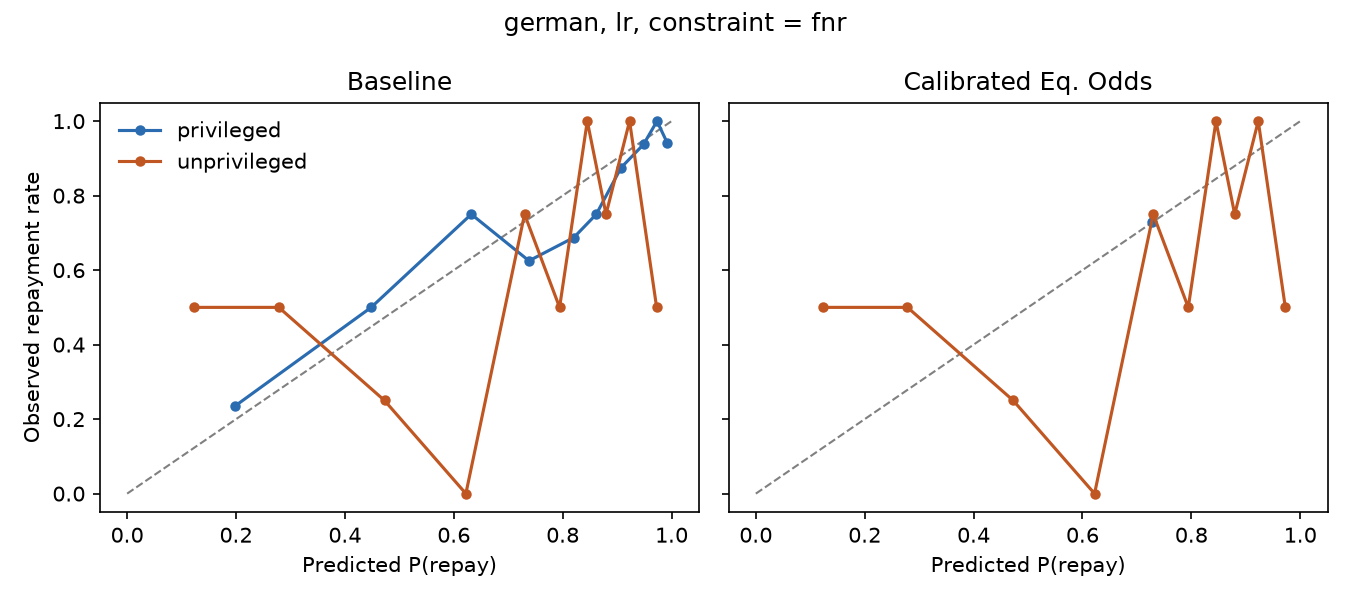

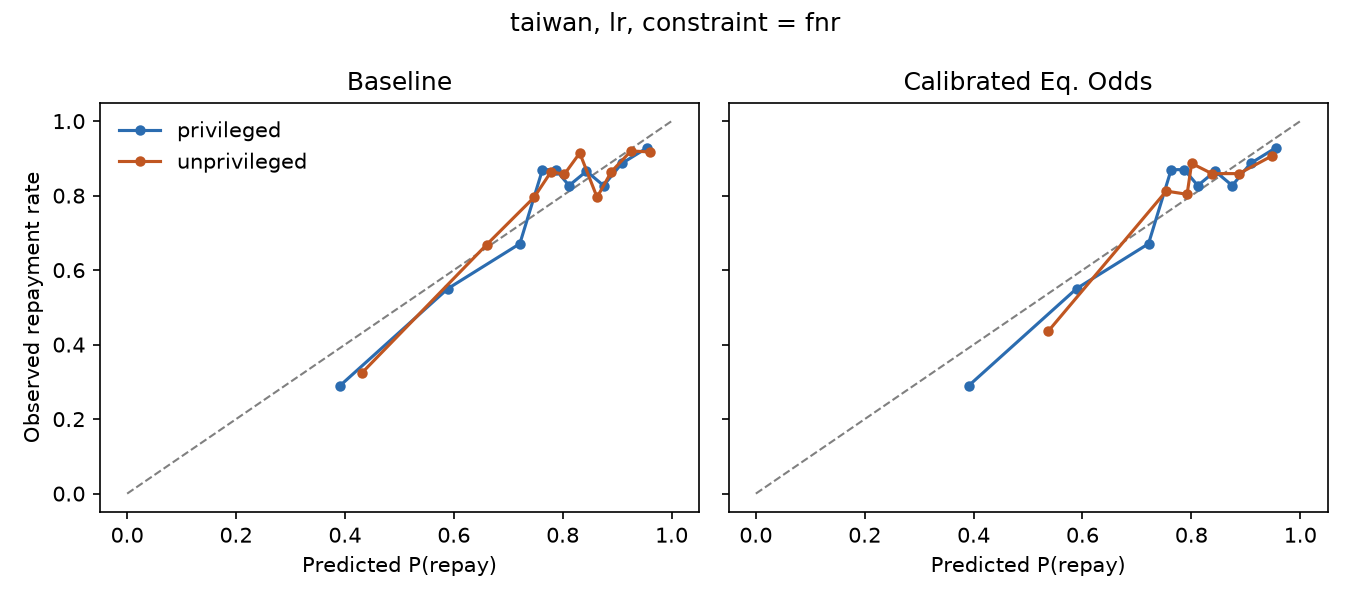

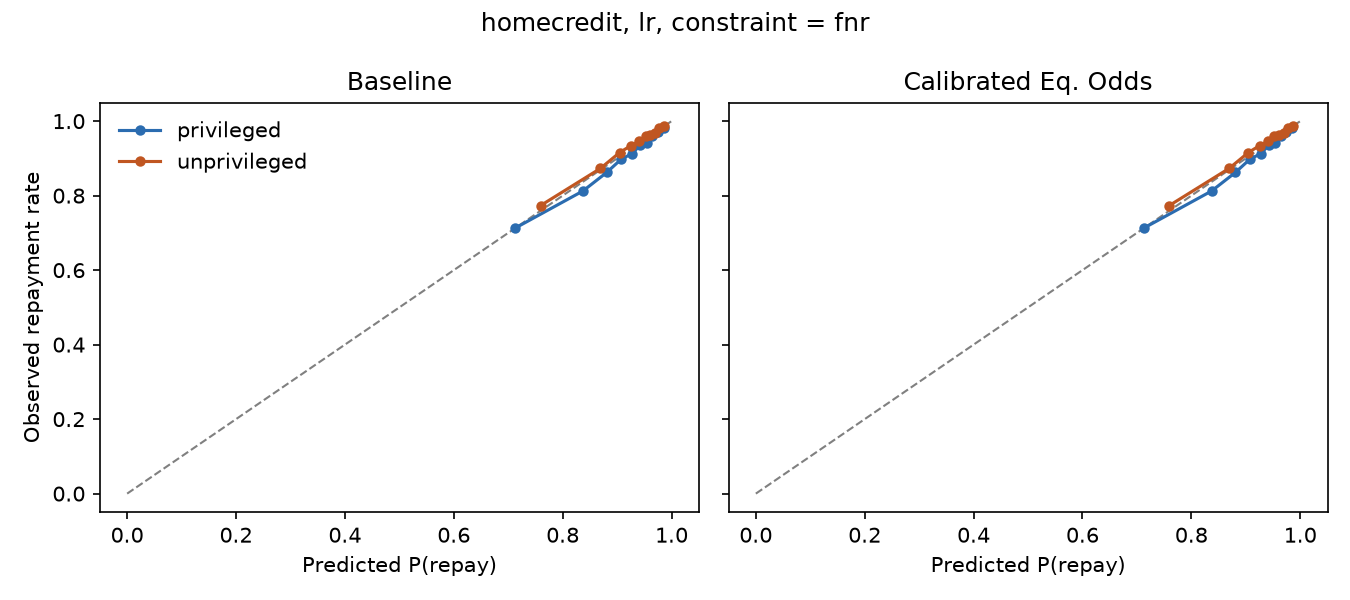

In [26]:
for name in DATASETS:
    display(Image(filename=str(Path(FIG_DIR) / f"{name}_{MODEL}_{CONSTRAINT}_reliability.png")))

## 7. Per-seed view of the all-or-nothing effect

Approval rate of each group after mitigation, per seed, next to the chosen cutoff.

In [27]:
(runs[runs.stage == "ceo"]
     .pivot_table(index=["dataset", "seed"], values=["threshold", "approval_priv", "approval_unpriv"])
     .round(3))

approval_priv  approval_unpriv  threshold
dataset    seed                                           
german     0             0.000            0.526      0.752
           1             1.000            0.395      0.709
           2             1.000            0.500      0.683
           3             1.000            0.553      0.602
           4             0.000            0.342      0.729
homecredit 0             0.599            0.691      0.918
           1             0.615            0.698      0.916
           2             0.585            1.000      0.921
           3             0.577            1.000      0.922
           4             0.566            0.664      0.924
taiwan     0             0.724            0.876      0.739
           1             0.794            0.897      0.715
           2             0.729            0.921      0.749
           3             0.743            0.952      0.736
           4             0.731            0.848      0.740